## Agentic RAG Pipeline

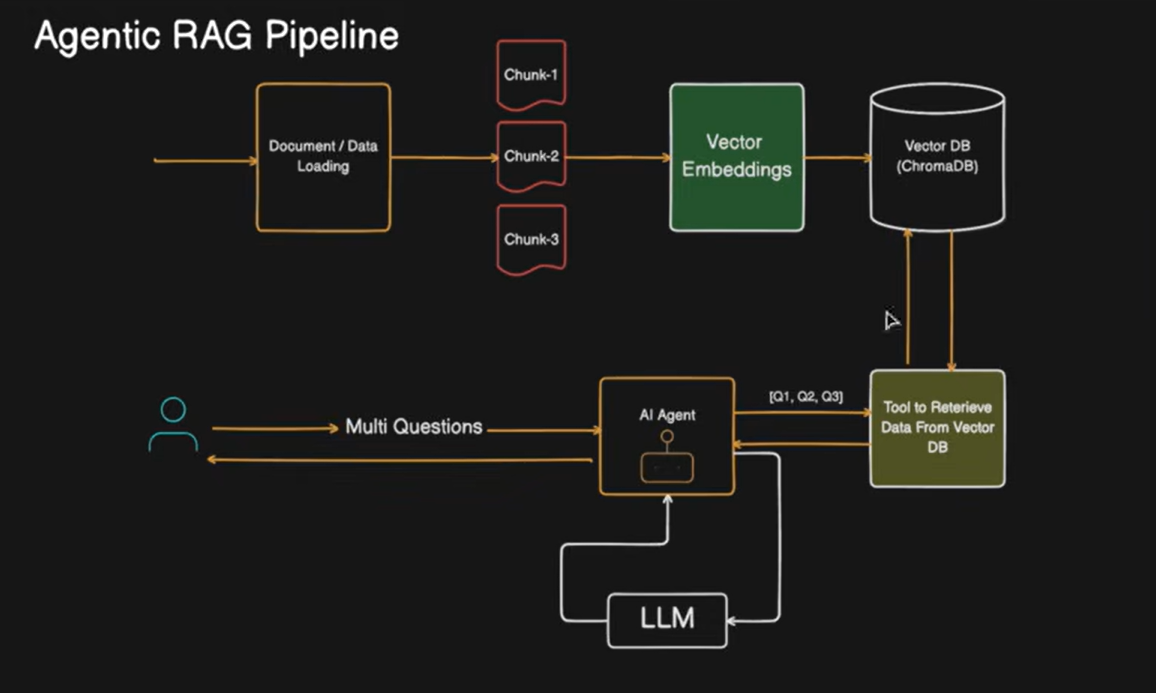

In [38]:
from dotenv import load_dotenv
load_dotenv()

True

In [51]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_google_genai import GoogleGenerativeAIEmbeddings, ChatGoogleGenerativeAI
from langchain_community.vectorstores import InMemoryVectorStore # we are using local memory
from langchain.tools import tool # function decirator
from langchain.agents import create_agent

In [40]:
pdf = PyPDFLoader(file_path="../data/Afraz_Ahmad_CV.pdf")
loaded_pdf = pdf.load()
len(loaded_pdf)

1

In [41]:
splitter = RecursiveCharacterTextSplitter(chunk_size=100, chunk_overlap=10)
splitted_pdf = splitter.split_documents(loaded_pdf)
len(splitted_pdf)


66

In [42]:
embedding = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")

In [43]:
vector_store = InMemoryVectorStore.from_documents(
    documents=splitted_pdf,
    embedding=embedding
)

In [44]:
# creating agent here
# we need 1. tool, 2. llm, 3. Prompt

In [45]:
@tool
def retrever_tool(query:str):
    """
        Function to retrieve relevant data from the vector_store based on the query.    
    """
    data = vector_store.similarity_search(query=query, k=4)

    context = ""
    for d in data:
        context += d.page_content + "\n"

    return context

In [52]:
llm = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite")

In [47]:
prompt = """

You are a helpful assistant that answers questions based on the context provided.

"""

In [54]:
agent = create_agent(
    model=llm,
    tools=[retrever_tool],
    system_prompt=prompt
)

In [58]:
question = "List down all the experties of Afraz, and the suitable jobs titles."
res = agent.invoke({
    "messages": [{
        "role": "user",
        "content": question
    }]
})

In [ ]:
answer = res["messages"][-1].content
answer

[{'type': 'text',
  'text': "Based on the information provided, here are the details regarding Afraz Ahmad's expertise and suitable job titles:\n\n**Expertise:**\n*   **Blockchain Development:** Hands-on experience with smart contracts and decentralized finance (DeFi).\n*   **Artificial Intelligence (AI):** Professional experience in the AI domain.\n*   **Crypto Compliance:** Knowledge and experience in compliance related to cryptocurrency.\n\n**Suitable Job Titles:**\nBased on his profile and professional background, the following job titles are suitable:\n*   Blockchain Developer\n*   AI Professional / AI Developer\n*   Crypto Compliance Specialist / Analyst\n*   DeFi Developer / Specialist",
  'extras': {'signature': 'EnMKcQFpFH0TxbMgd0/yFNMlNDC4OuCkdyuEtJCDStfwrJ7vu+K9I9xrf8z0afYul9Lz3Wdz4IMV84hIlnulEorv62DJ52GMgW9KuTgG0RhUWkvlmcb3Px+q/HavjKNnp+8603cxWkK9UkJ6lTZgPArq63wC'}}]